In [10]:
!pip install transformers gradio -q
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from transformers.utils import logging
import warnings
warnings.filterwarnings('ignore')
logging.set_verbosity_error()

MODEL = 'Qwen/Qwen2.5-0.5B-Instruct'

print('Loading chatbot model...')
tokenizer = AutoTokenizer.from_pretrained(MODEL)
model=AutoModelForCausalLM.from_pretrained(MODEL)
print('Chatbot ready!')


Loading chatbot model...


ModuleNotFoundError: Could not import module 'Qwen2ForCausalLM'. Are this object's requirements defined correctly? Set the logging verbosity to DEBUG for the original import error.

In [11]:
!pip install --force-reinstall --no-cache-dir torch==2.6.0 torchvision==0.21.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 766.6/766.6 MB 94.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 132.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 105.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 83.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 93.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 83.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 197.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 134.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 141.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 177.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 77.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 150.1/150.1 MB 159.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [1]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
GPU available: True


In [2]:
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL = "Qwen/Qwen2.5-0.5B-Instruct"

print("Loading chatbot model...")

tokenizer = AutoTokenizer.from_pretrained(MODEL)

model = AutoModelForCausalLM.from_pretrained(MODEL)

print("JAD chatbot ready!")

Loading chatbot model...


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

JAD chatbot ready!


In [14]:

def chat(user_message, history=None):
    history = history or []

    messages = [
        {
            "role": "system",
            "content": "You are JAD, a friendly and helpful AI chatbot."
        }
    ]
    messages.extend(history)
    messages.append({
        "role": "user",
        "content": user_message
    })

    # Get tokenized input
    encoded = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    )

    # Extract the actual tensor
    input_ids = encoded["input_ids"].to(model.device)

    # Include attention mask when available
    attention_mask = encoded.get("attention_mask")
    if attention_mask is not None:
        attention_mask = attention_mask.to(model.device)

    with torch.inference_mode():
        outputs = model.generate(
            input_ids=input_ids,
            attention_mask=attention_mask,
            max_new_tokens=150,
            do_sample=True,
            temperature=0.7,
            pad_token_id=tokenizer.eos_token_id
        )

    # Decode only JAD's new response
    input_length = input_ids.shape[1]
    reply = tokenizer.decode(
        outputs[0][input_length:],
        skip_special_tokens=True
    ).strip()

    history = history + [
        {"role": "user", "content": user_message},
        {"role": "assistant", "content": reply}
    ]

    return reply, history


In [15]:
history = []

reply, history = chat("What is football?", history)
print("You:", "What is football?")
print("JAD:", reply)

You: What is football?
JAD: Football, commonly known as soccer or simply "soccer," is a team sport played on a rectangular field with a goalpost at each end. The objective of the game is to score goals by kicking a ball into the opposing team's goal from a distance controlled by the referee.

The rules vary widely across different countries and leagues, but generally include:

1. **Field Size**: A standard football field is 90 meters long (300 feet) and 45 meters wide (150 feet), although smaller fields have been used in some competitions.
2. **Goalposts**: There are two goalposts for each team, positioned 7.2 meters (23 feet) high and 6.5 meters (21


In [11]:
import torch

inputs = tokenizer.apply_chat_template(
    [{"role": "user", "content": "Hello"}],
    tokenize=True,
    add_generation_prompt=True,
    return_tensors="pt",
    return_dict=True
)

input_ids = inputs["input_ids"]

print("Input IDs type:", type(input_ids))
print("Input shape:", input_ids.shape)

Input IDs type: <class 'torch.Tensor'>
Input shape: torch.Size([1, 30])


In [16]:
# Fresh start
history = []

# Message 1 — tell it something
reply1, history = chat('My favourite sport is cricket.', history)
print('You : My favourite sport is cricket.')
print('Bot :', reply1)
print()

# Message 2 — ask a follow-up
reply2, history = chat('What sport did I just mention?', history)
print('You : What sport did I just mention?')
print('Bot :', reply2)
print()
print('The bot should remember cricket!')


You : My favourite sport is cricket.
Bot : That's great to hear! Cricket is a popular sport that brings people together through shared excitement and passion for the game. If you're interested in learning more about cricket or just want some fun trivia, I'd be happy to have an engaging conversation with you about it!

You : What sport did I just mention?
Bot : You mentioned cricket, which is indeed one of the most popular sports worldwide. It involves batting (throwing the ball), bowling (picking up balls), running, hitting the ball with your bat, fielding (receiving the ball), and scoring runs by hitting the ball over the boundary line. The rules vary depending on the country, but they generally involve fast-paced, intense play and require teamwork and strategy. Enjoy playing cricket!

The bot should remember cricket!


In [18]:
# Fresh start
history = []

questions = [
    'Tell me about smart veichles.',
    'What sensors are used in smart veichles?',
    'How does AI help manage traffic?',
    'What are the benefits for citizens?',
]

print('Full conversation about Smart veichles:')
print('=' * 45)
print()

for i, question in enumerate(questions, 1):
    reply, history = chat(question, history)
    print(f'Turn {i}')
    print(f'You : {question}')
    print(f'Bot : {reply}')
    print()


Full conversation about Smart veichles:

Turn 1
You : Tell me about smart veichles.
Bot : Smart Veichle is an innovative technology that aims to enhance the efficiency of traffic management systems by using artificial intelligence (AI) and machine learning algorithms. Here's a brief overview:

1. **Real-time Traffic Monitoring**: Smart Veichles use advanced sensors and cameras to monitor real-time traffic conditions on roads.

2. **Predictive Analytics**: By analyzing historical data, the system can predict future traffic patterns and congestion areas. This helps in better allocation of resources such as traffic lights, police officers, and emergency services.

3. **Automatic Traffic Control**: Based on predictive analytics, vehicles can be directed towards designated lanes or paths automatically. This reduces delays and accidents caused by unexpected vehicle movements.

4. **Traffic Flow Optimization**: The system optimizes traffic

Turn 2
You : What sensors are used in smart veichles

In [19]:
# ✏️ Change these questions!
history = []

my_questions = [
    'Tell me about Data analaytics.',
    'How is it different from other domain like fullstack etc?',
    'Can you give me a simple example?',
]

for i, question in enumerate(my_questions, 1):
    reply, history = chat(question, history)
    print(f'You : {question}')
    print(f'Bot : {reply}')
    print()


You : Tell me about Data analaytics.
Bot : Data analytics is the process of extracting insights from data to make informed decisions or predictions. It involves using statistical methods, machine learning algorithms, and other techniques to analyze large volumes of data in order to uncover patterns, trends, correlations, and other meaningful information.

Key components of data analytics include:

1. **Data Collection**: Gathering raw data from various sources such as databases, sensors, and user interactions.
2. **Data Cleaning**: Preparing the collected data for analysis by removing duplicates, correcting errors, and ensuring accuracy.
3. **Data Storage**: Efficiently storing and managing data that can be analyzed quickly.
4. **Data Processing**: Transforming raw data into usable forms for analysis.
5. **Analysis Tools**: Using tools like SQL, Python

You : How is it different from other domain like fullstack etc?
Bot : Data Analytics can be considered distinct from other domains suc

In [20]:
!pip install -q diffusers transformers accelerate safetensors

In [21]:
import torch
from diffusers import StableDiffusionPipeline
from IPython.display import display

device = "cuda" if torch.cuda.is_available() else "cpu"

image_pipe = StableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    torch_dtype=torch.float16 if device == "cuda" else torch.float32
).to(device)

print("JAD image generator is ready!")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

JAD image generator is ready!


In [25]:
def jad_image(prompt):
    result = image_pipe(
        prompt=prompt,
        num_inference_steps=20,
        guidance_scale=7.0
    )

    generated_image = result.images[0]

    return generated_image

  0%|          | 0/20 [00:00<?, ?it/s]

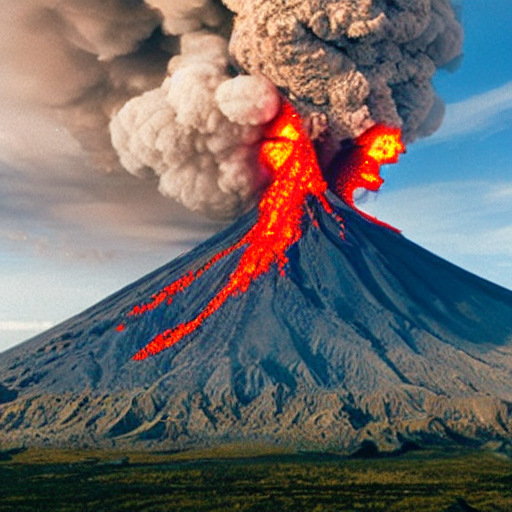

In [26]:
jad_image("A volcanic eruption")

In [28]:

%pip install -q -U gradio


In [29]:

import gradio as gr
import torch

# =========================================
# JAD AI CHATBOT + IMAGE GENERATOR
# Requires: model, tokenizer, image_pipe
# =========================================

assert model is not None, "Load your Qwen model first."
assert tokenizer is not None, "Load your tokenizer first."
assert image_pipe is not None, "Load your Stable Diffusion model first."


SYSTEM_PROMPT = """
You are JAD, a friendly and helpful AI assistant.
Answer clearly and accurately in simple language.
"""


# Detect requests to generate images
def is_image_request(text):
    text = text.lower().strip()

    triggers = [
        "generate an image",
        "generate image",
        "create an image",
        "create image",
        "make an image",
        "make image",
        "generate a picture",
        "create a picture",
        "make a picture",
        "picture of",
        "image of",
        "draw ",
        "paint "
    ]

    return any(word in text for word in triggers)


# Convert a request into an image prompt
def get_image_prompt(text):
    prompt = text.strip()

    prefixes = [
        "generate an image of ",
        "generate an image ",
        "generate image of ",
        "generate image ",
        "create an image of ",
        "create an image ",
        "create image of ",
        "create image ",
        "make an image of ",
        "make an image ",
        "make image of ",
        "make image ",
        "generate a picture of ",
        "generate a picture ",
        "create a picture of ",
        "create a picture ",
        "make a picture of ",
        "make a picture ",
        "draw ",
        "paint "
    ]

    for prefix in prefixes:
        if prompt.lower().startswith(prefix):
            prompt = prompt[len(prefix):].strip()
            break

    return prompt or text


# Generate one image
def generate_jad_image(prompt):
    result = image_pipe(
        prompt=prompt,
        num_inference_steps=20,
        guidance_scale=7.0
    )

    return result.images[0]


# Generate a text answer using Qwen
def generate_jad_text(message, history):
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT}
    ]

    # History is stored as dictionaries in the app
    for item in history:
        if not isinstance(item, dict):
            continue

        role = item.get("role")
        content = item.get("content")

        if role in ("user", "assistant") and isinstance(content, str):
            if content.strip():
                messages.append({
                    "role": role,
                    "content": content
                })

    messages.append({
        "role": "user",
        "content": message
    })

    encoded = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    )

    encoded = {
        key: value.to(model.device)
        for key, value in encoded.items()
        if isinstance(value, torch.Tensor)
    }

    with torch.inference_mode():
        output = model.generate(
            **encoded,
            max_new_tokens=200,
            do_sample=True,
            temperature=0.7,
            pad_token_id=tokenizer.eos_token_id
        )

    input_length = encoded["input_ids"].shape[1]

    answer = tokenizer.decode(
        output[0][input_length:],
        skip_special_tokens=True
    ).strip()

    return answer or "I couldn't generate an answer. Please try again."


# Main chat handler
def respond(message, history):
    history = list(history or [])

    if not message or not message.strip():
        return history, None, ""

    try:
        if is_image_request(message):
            prompt = get_image_prompt(message)

            # Generate the image once
            generated_image = generate_jad_image(prompt)

            history.extend([
                {"role": "user", "content": message},
                {
                    "role": "assistant",
                    "content": "🎨 Your image is ready! See the preview."
                }
            ])

            return history, generated_image, ""

        # Normal text question
        answer = generate_jad_text(message, history)

        history.extend([
            {"role": "user", "content": message},
            {"role": "assistant", "content": answer}
        ])

        return history, None, ""

    except Exception as error:
        history.extend([
            {"role": "user", "content": message},
            {
                "role": "assistant",
                "content": f"Sorry, an error occurred: {error}"
            }
        ])

        return history, None, ""


# =========================================
# COLORFUL JAD INTERFACE
# =========================================

css = """
.gradio-container {
    background: linear-gradient(
        135deg, #0b1020, #21133d, #101c32
    ) !important;
    color: white !important;
}

#jad-title {
    text-align: center;
    font-size: 42px;
    font-weight: 800;
    background: linear-gradient(
        90deg, #00e5ff, #a78bfa, #ff70c8
    );
    -webkit-background-clip: text;
    -webkit-text-fill-color: transparent;
}

#jad-subtitle {
    text-align: center;
    color: #c4c9e8;
}

#chatbot, #preview {
    border: 1px solid #554581;
    border-radius: 18px;
}

#send-button {
    background: linear-gradient(90deg, #7257ff, #00bcd4);
    color: white;
    border: none;
}
"""


with gr.Blocks(title="JAD AI") as app:

    gr.Markdown(
        "# ✨ JAD AI",
        elem_id="jad-title"
    )

    gr.Markdown(
        "Your AI companion for conversations and creativity",
        elem_id="jad-subtitle"
    )

    with gr.Row():

        with gr.Column(scale=3):

            chatbot = gr.Chatbot(
                label="💬 Chat with JAD",
                height=480,
                elem_id="chatbot"
            )

            message = gr.Textbox(
                label="Message JAD",
                placeholder=(
                    "Ask a question, or type "
                    "'Generate an image of a sports car'..."
                ),
                lines=2
            )

            with gr.Row():

                send_button = gr.Button(
                    "✨ Send",
                    elem_id="send-button"
                )

                clear_button = gr.Button("🗑️ New chat")

        with gr.Column(scale=2):

            preview = gr.Image(
                label="🎨 Generated image",
                type="pil",
                height=400,
                elem_id="preview"
            )

            gr.Markdown("""
            ### Try JAD

            💬 **Ask:** What is artificial intelligence?

            🎨 **Generate:** Generate an image of a futuristic city.

            🖌️ **Draw:** Draw a cute robot playing football.
            """)

    message.submit(
        respond,
        inputs=[message, chatbot],
        outputs=[chatbot, preview, message]
    )

    send_button.click(
        respond,
        inputs=[message, chatbot],
        outputs=[chatbot, preview, message]
    )

    clear_button.click(
        lambda: ([], None, ""),
        inputs=[],
        outputs=[chatbot, preview, message]
    )


# Gradio 6: theme and CSS belong in launch()
app.queue().launch(
    share=True,
    theme=gr.themes.Soft(
        primary_hue="violet",
        secondary_hue="cyan",
        neutral_hue="slate"
    ),
    css=css
)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d8673af4b41d1ca45f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Image model loaded: True


  0%|          | 0/20 [00:00<?, ?it/s]

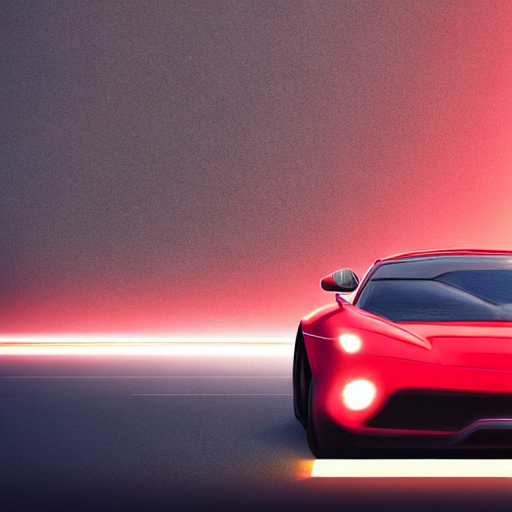

In [30]:
print("Image model loaded:", image_pipe is not None)

result = image_pipe(
    prompt="A realistic red sports car on a futuristic neon-lit road",
    num_inference_steps=20,
    guidance_scale=7.0
)

display(result.images[0])

In [31]:
def is_image_request(text):
    text = text.lower().strip()

    triggers = [
        "generate",
        "create an image",
        "create image",
        "make an image",
        "make image",
        "draw",
        "paint",
        "picture of",
        "image of",
        "show me a picture",
        "illustration of"
    ]

    return any(word in text for word in triggers)

In [32]:
def respond(message, history):
    history = list(history or [])

    if not message or not message.strip():
        return history, None, ""

    try:
        if is_image_request(message):
            prompt = get_image_prompt(message)

            history.append({
                "role": "user",
                "content": message
            })

            history.append({
                "role": "assistant",
                "content": "🎨 Generating your image..."
            })

            generated_image = generate_jad_image(prompt)

            history[-1]["content"] = "✨ Your image is ready!"
            return history, generated_image, ""

        answer = generate_jad_text(message, history)

        history.extend([
            {"role": "user", "content": message},
            {"role": "assistant", "content": answer}
        ])

        return history, None, ""

    except Exception as error:
        history.append({
            "role": "assistant",
            "content": f"⚠️ Error: {str(error)}"
        })
        return history, None, ""

In [33]:

import gradio as gr
import torch

SYSTEM_PROMPT = """
You are JAD, a friendly AI assistant.
Give helpful answers in simple English.
You can chat and generate images when requested.
"""

def chat_with_jad(message, history):
    history = history or []

    if not message.strip():
        return history, None, ""

    try:
        # Generate an image when requested
        image_words = [
            "generate an image", "generate image",
            "create an image", "create image",
            "draw ", "paint ", "picture of", "image of"
        ]

        if any(word in message.lower() for word in image_words):
            prompt = message
            for prefix in [
                "generate an image of ", "generate an image ",
                "generate image of ", "generate image ",
                "create an image of ", "create an image ",
                "create image of ", "create image ",
                "draw ", "paint "
            ]:
                if prompt.lower().startswith(prefix):
                    prompt = prompt[len(prefix):].strip()
                    break

            result = image_pipe(
                prompt=prompt,
                num_inference_steps=20,
                guidance_scale=7
            )

            history = history + [
                {"role": "user", "content": message},
                {"role": "assistant", "content": "🎨 Image generated successfully!"}
            ]
            return history, result.images[0], ""

        # Normal text chat
        messages = [{"role": "system", "content": SYSTEM_PROMPT}]

        for item in history:
            if isinstance(item, dict):
                role = item.get("role")
                content = item.get("content")
                if role in ["user", "assistant"] and isinstance(content, str):
                    messages.append({"role": role, "content": content})

        messages.append({"role": "user", "content": message})

        inputs = tokenizer.apply_chat_template(
            messages,
            tokenize=True,
            add_generation_prompt=True,
            return_tensors="pt",
            return_dict=True
        )

        inputs = {
            k: v.to(model.device)
            for k, v in inputs.items()
            if isinstance(v, torch.Tensor)
        }

        with torch.inference_mode():
            output = model.generate(
                **inputs,
                max_new_tokens=200,
                do_sample=True,
                temperature=0.7,
                pad_token_id=tokenizer.eos_token_id
            )

        input_length = inputs["input_ids"].shape[1]
        answer = tokenizer.decode(
            output[0][input_length:],
            skip_special_tokens=True
        ).strip()

        history = history + [
            {"role": "user", "content": message},
            {"role": "assistant", "content": answer}
        ]

        return history, None, ""

    except Exception as e:
        history = history + [
            {"role": "assistant", "content": f"Error: {e}"}
        ]
        return history, None, ""


css = """
.gradio-container {
    background: linear-gradient(135deg, #10152b, #321653, #092b3d);
    color: white;
}
#jad-title {
    text-align: center;
    font-size: 42px;
    font-weight: 800;
    color: #00e5ff;
}
"""

with gr.Blocks(title="JAD AI") as demo:
    gr.Markdown("# ✨ JAD AI", elem_id="jad-title")
    gr.Markdown("### Your AI chatbot • Text conversations • Image creation")

    with gr.Row():
        with gr.Column(scale=3):
            chatbot = gr.Chatbot(label="💬 Chat with JAD", height=450)
            message = gr.Textbox(
                placeholder="Ask JAD anything or say: Generate an image of a car",
                label="Your message"
            )

            with gr.Row():
                send = gr.Button("🚀 Send", variant="primary")
                clear = gr.Button("🗑️ Clear chat")

        with gr.Column(scale=2):
            image_output = gr.Image(
                label="🎨 Image generated by JAD",
                height=400
            )

    send.click(
        chat_with_jad,
        inputs=[message, chatbot],
        outputs=[chatbot, image_output, message]
    )

    message.submit(
        chat_with_jad,
        inputs=[message, chatbot],
        outputs=[chatbot, image_output, message]
    )

    clear.click(
        lambda: ([], None, ""),
        outputs=[chatbot, image_output, message]
    )

demo.queue().launch(share=True, css=css)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9d8b04d4c4f5f9fea6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
